# Plots for Football investigations

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import warnings

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [2]:
# Helperfunctions
def plot_per_season_per_country(df, y, fit_reg=True):
    seasons = [14, 15, 16, 17, 18]
    sns.lmplot(x="season", y=y,
               hue="country", data=df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    sumed_df = pd.DataFrame()
    sumed_df["season"] = seasons
    total = []
    for season in seasons:
        total.append(np.sum(df.groupby(["season"]).get_group(
            season)[y]) / NUM_OF_COUNTRIES)
    sumed_df[y] = total
    sns.lmplot(x="season", y=y,
               data=sumed_df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    plt.show()


## Homefield advantage

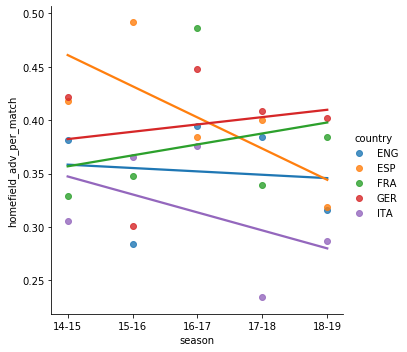

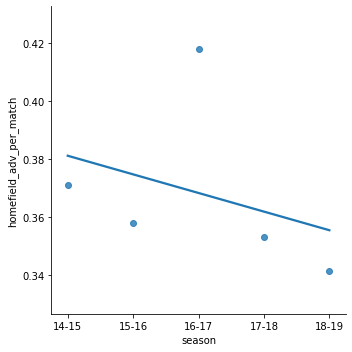

In [3]:
df_homefield = pd.read_csv('data/plot_homefield_adv.csv', sep=';')
plot_per_season_per_country(df_homefield, y="homefield_adv_per_match")


## Goalamount per match

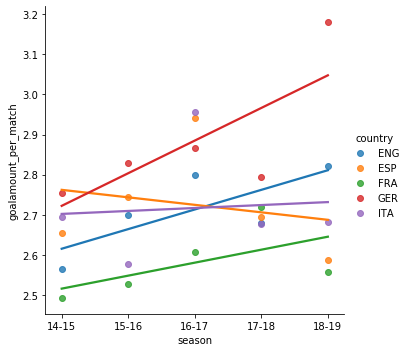

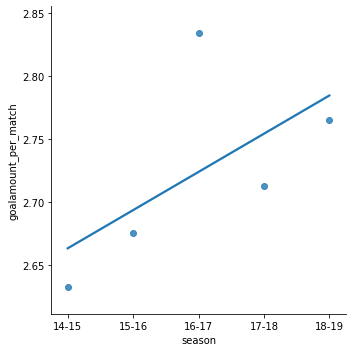

In [4]:
df_goalamount = pd.read_csv('data/plot_goalamount.csv', sep=';')
plot_per_season_per_country(df_goalamount, "goalamount_per_match")


## Goalchances per match

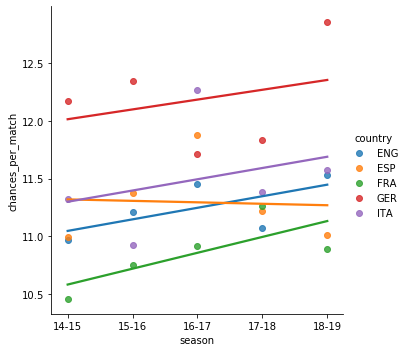

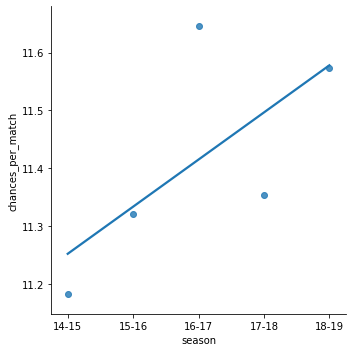

In [5]:
df_chances = pd.read_csv('data/plot_chances.csv', sep=';')
plot_per_season_per_country(df_chances, "chances_per_match")


## Market value 

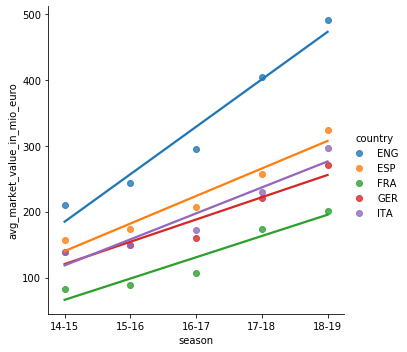

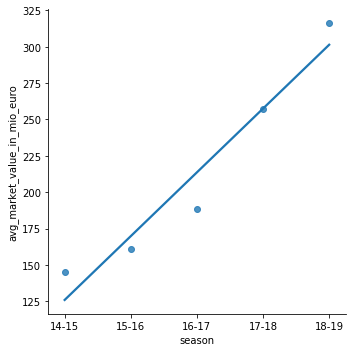

In [9]:
df_market_value = pd.read_csv('data/plot_market_value.csv', sep=';')
plot_per_season_per_country(df_market_value, "avg_market_value_in_mio_euro")


## Market value variance

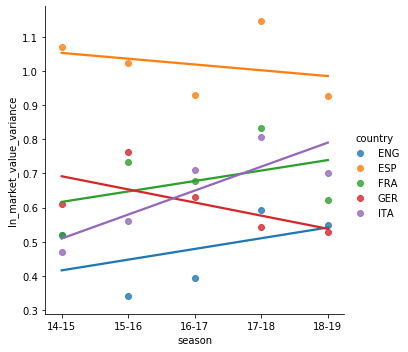

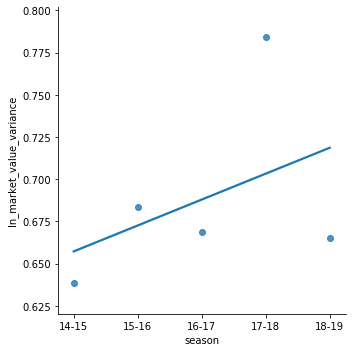

In [12]:
df_market_value_variance = pd.read_csv(
    'data/plot_ln_market_value_variance.csv', sep=';')
plot_per_season_per_country(
    df_market_value_variance, "ln_market_value_variance")
